In [ ]:
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
%matplotlib inline

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

words = open('/content/drive/MyDrive/Colab Notebooks/Karpathy Zero to Hero/names', 'r').read().splitlines()
words[:8], len(words)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


(['emma', 'olivia', 'ava', 'isabella', 'sophia', 'charlotte', 'mia', 'amelia'],
 32033)

In [ ]:
# build the vocabulary of characters and mappings to/from integers
chars = sorted(list(set(''.join(words))))
stoi = {s:i+1 for i,s in enumerate(chars)}
stoi['.'] = 0
itos = {i:s for s,i in stoi.items()}
vocab_size = len(itos)
print(itos)
print(vocab_size)

{1: 'a', 2: 'b', 3: 'c', 4: 'd', 5: 'e', 6: 'f', 7: 'g', 8: 'h', 9: 'i', 10: 'j', 11: 'k', 12: 'l', 13: 'm', 14: 'n', 15: 'o', 16: 'p', 17: 'q', 18: 'r', 19: 's', 20: 't', 21: 'u', 22: 'v', 23: 'w', 24: 'x', 25: 'y', 26: 'z', 0: '.'}
27


In [ ]:
# build the dataset
block_size = 3 # context length: how many characters do we take to predict the next one?

def build_dataset(words):
  X, Y = [], []

  for w in words:
    context = [0] * block_size
    for ch in w + '.':
      ix = stoi[ch]
      X.append(context)
      Y.append(ix)
      context = context[1:] + [ix] # crop and append

  X = torch.tensor(X)
  Y = torch.tensor(Y)
  print(X.shape, Y.shape)
  return X, Y

import random
random.seed(42)
random.shuffle(words)
n1 = int(0.8*len(words))
n2 = int(0.9*len(words))

Xtr,  Ytr  = build_dataset(words[:n1])     # 80%
Xdev, Ydev = build_dataset(words[n1:n2])   # 10%
Xte,  Yte  = build_dataset(words[n2:])     # 10%

torch.Size([182625, 3]) torch.Size([182625])
torch.Size([22655, 3]) torch.Size([22655])
torch.Size([22866, 3]) torch.Size([22866])


In [ ]:
# MLP revisited
n_embd = 10 # the dimensionality of the character embedding vectors
n_hidden = 200 # the number of neurons in the hidden layer of the MLP

g = torch.Generator().manual_seed(2147483647) # for reproducibility
C  = torch.randn((vocab_size, n_embd),            generator=g)
W1 = torch.randn((n_embd * block_size, n_hidden), generator=g)
b1 = torch.randn(n_hidden,                        generator=g)
W2 = torch.randn((n_hidden, vocab_size),          generator=g)
b2 = torch.randn(vocab_size,                      generator=g)

parameters = [C, W1, b1, W2, b2]
print(sum(p.nelement() for p in parameters)) # number of parameters in total
for p in parameters:
  p.requires_grad = True

11897


In [ ]:
# same optimization as last time
max_steps = 200000
batch_size = 32
lossi = []

for i in range(max_steps):

  # minibatch construct
  ix = torch.randint(0, Xtr.shape[0], (batch_size,), generator=g)
  Xb, Yb = Xtr[ix], Ytr[ix] # batch X,Y

  # forward pass
  emb = C[Xb] # embed the characters into vectors
  embcat = emb.view(emb.shape[0], -1) # concatenate the vectors
  hpreact = embcat @ W1 + b1 # hidden layer pre-activation
  h = torch.tanh(hpreact) # hidden layer
  logits = h @ W2 + b2 # output layer
  loss = F.cross_entropy(logits, Yb) # loss function

  # backward pass
  for p in parameters:
    p.grad = None
  loss.backward()

  # update
  lr = 0.1 if i < 100000 else 0.01 # step learning rate decay
  for p in parameters:
    p.data += -lr * p.grad

  # track stats
  if i % 10000 == 0: # print every once in a while
    print(f'{i:7d}/{max_steps:7d}: {loss.item():.4f}')
  lossi.append(loss.log10().item())

      0/ 200000: 27.8817
  10000/ 200000: 2.9415
  20000/ 200000: 2.5069
  30000/ 200000: 2.7998
  40000/ 200000: 2.0261
  50000/ 200000: 2.5863
  60000/ 200000: 2.3420
  70000/ 200000: 2.0952
  80000/ 200000: 2.3454
  90000/ 200000: 2.2365
 100000/ 200000: 2.1080
 110000/ 200000: 2.3831
 120000/ 200000: 1.9898
 130000/ 200000: 2.4591
 140000/ 200000: 2.1910
 150000/ 200000: 2.1606
 160000/ 200000: 2.1811
 170000/ 200000: 1.7997
 180000/ 200000: 2.0962
 190000/ 200000: 1.8052


In [ ]:
@torch.no_grad() # this decorator disables gradient tracking
def split_loss(split):
  x,y = {
    'train': (Xtr, Ytr),
    'val': (Xdev, Ydev),
    'test': (Xte, Yte),
  }[split]
  emb = C[x] # (N, block_size, n_embd)
  embcat = emb.view(emb.shape[0], -1) # concat into (N, block_size * n_embd)
  h = torch.tanh(embcat @ W1 + b1) # (N, n_hidden)
  logits = h @ W2 + b2 # (N, vocab_size)
  loss = F.cross_entropy(logits, y)
  print(split, loss.item())

split_loss('train')
split_loss('val')

train 2.127678871154785
val 2.1750576496124268


In [ ]:
# sample from the model

g = torch.Generator().manual_seed(2147483647 + 10)

for _ in range(20):

  out = []
  context = [0] * block_size

  while True:
    emb = C[torch.tensor([context])]
    h = torch.tanh(emb.view(1, -1) @ W1 + b1)
    logits = h @ W2 + b2
    probs = F.softmax(logits, dim=1)
    ix = torch.multinomial(probs, num_samples=1, generator=g).item()
    context = context[1:] + [ix]
    out.append(ix)
    if ix == 0:
      break

  print(''.join(itos[i] for i in out))

carlah.
amille.
khy.
myli.
taty.
skanden.
jazonen.
amerynchireei.
nellara.
chaiir.
kaleigh.
ham.
jorn.
quint.
salin.
alianni.
wanthoniearyn.
kai.
everusabee.
demiia.


# Optimizing the MLP

There is still lot's of room for improvement of the MLP, starting with the very beginning of the optimization process - we see that the loss usually starts at 25+. Thinking logically, a model with a uniform prior would predict each of the next 27 characters with equal probability = 1/27. So, the expected loss for such a model would be...

In [ ]:
-torch.tensor([1/27]).log().item()

3.295836925506592

27+ loss is much worse than 3.29, suggesting that the model is often confidently wrong. (assigning high probabilities to characters that do not end up getting predicted).

In [ ]:
logits = torch.tensor([0, 0, 0, 5]).float()
probs = torch.softmax(logits, dim=0)
loss = -probs[2].log()
probs, loss # base loss w/ uniform dist = 1.386
# loss increases to 10 because model was confident in wrong answer

(tensor([0.0066, 0.0066, 0.0066, 0.9802]), tensor(5.0200))

In [ ]:
logits = torch.randn(4) * 10
probs = torch.softmax(logits, dim=0)
loss = -probs[2].log()
probs, loss # base loss w/ uniform dist = 1.386
# when the logits are extreme, loss increases (loss can even become Inf due to some floating point shenanigans)

(tensor([1.0373e-02, 9.8957e-01, 1.1380e-06, 5.2525e-05]), tensor(13.6862))

We can get around this by reducing the weights' magnitude, bringing them closer to 0 (technically, the weights don't need to equal 0, they just need to be equal).

In [ ]:
# MLP revisited
n_embd = 10 # the dimensionality of the character embedding vectors
n_hidden = 200 # the number of neurons in the hidden layer of the MLP

g = torch.Generator().manual_seed(2147483647) # for reproducibility
C  = torch.randn((vocab_size, n_embd),            generator=g)
W1 = torch.randn((n_embd * block_size, n_hidden), generator=g)
b1 = torch.randn(n_hidden,                        generator=g)
W2 = torch.randn((n_hidden, vocab_size),          generator=g) * 0.01 # reducing magnitude
b2 = torch.randn(vocab_size,                      generator=g) * 0 #initializing at 0

parameters = [C, W1, b1, W2, b2]
print(sum(p.nelement() for p in parameters)) # number of parameters in total
for p in parameters:
  p.requires_grad = True

11897


In [ ]:
# same optimization as last time
max_steps = 200000
batch_size = 32
lossi = []

for i in range(max_steps):

  # minibatch construct
  ix = torch.randint(0, Xtr.shape[0], (batch_size,), generator=g)
  Xb, Yb = Xtr[ix], Ytr[ix] # batch X,Y

  # forward pass
  emb = C[Xb] # embed the characters into vectors
  embcat = emb.view(emb.shape[0], -1) # concatenate the vectors
  hpreact = embcat @ W1 + b1 # hidden layer pre-activation
  h = torch.tanh(hpreact) # hidden layer
  logits = h @ W2 + b2 # output layer
  loss = F.cross_entropy(logits, Yb) # loss function

  # backward pass
  for p in parameters:
    p.grad = None
  loss.backward()

  # update
  lr = 0.1 if i < 100000 else 0.01 # step learning rate decay
  for p in parameters:
    p.data += -lr * p.grad

  # track stats
  if i % 10000 == 0: # print every once in a while
    print(f'{i:7d}/{max_steps:7d}: {loss.item():.4f}')
  lossi.append(loss.log10().item())

      0/ 200000: 3.3221
  10000/ 200000: 2.1900
  20000/ 200000: 2.4196
  30000/ 200000: 2.6067
  40000/ 200000: 2.0601
  50000/ 200000: 2.4988
  60000/ 200000: 2.3902
  70000/ 200000: 2.1344
  80000/ 200000: 2.3369
  90000/ 200000: 2.1299
 100000/ 200000: 1.8329
 110000/ 200000: 2.2053
 120000/ 200000: 1.8540
 130000/ 200000: 2.4566
 140000/ 200000: 2.1879
 150000/ 200000: 2.1118
 160000/ 200000: 1.8956
 170000/ 200000: 1.8644
 180000/ 200000: 2.0326
 190000/ 200000: 1.8417


Even though the loss now looks reasonable, there is still a deeper initialization problem present in the first hidden layer of the network that requires inspection.

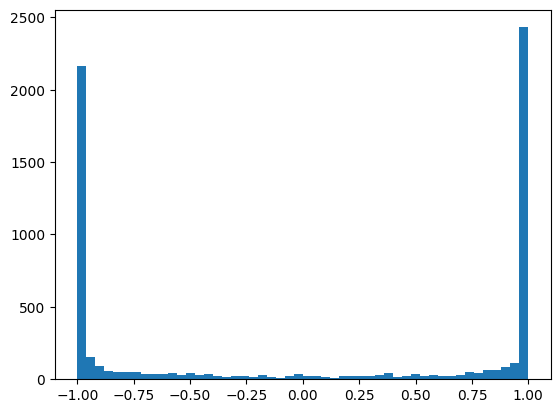

In [ ]:
plt.hist(h.view(-1).tolist(), 50);

We can see that the tanh is very active, squashing lots of values to -1 or 1. This is because we have a wide range of values pre-tanh operation:

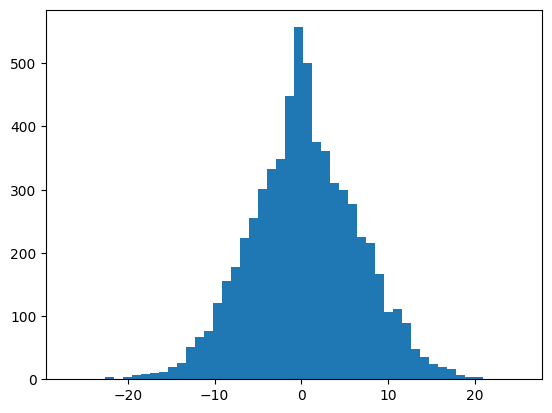

In [ ]:
plt.hist(hpreact.view(-1).tolist(), 50);

This is a worry because of a particularity in how the backward pass is performed. Looking at the tanh backward pass code:

In [ ]:
def _backward():
  self.grad += (1 - t**2) * out.grad
  out._backward = _backward

When |t| = 1, the gradient propagating through vanishes/is destroyed/set to 0. And we know that |t| = 1 when the output of the neuron for some input is 1. This means that, for some training data and neuron pair (with tanh smoothing), it is possible for the neuron to never "learn" because the gradient is always zeroed out at said neuron. And if, for some neuron, this is the case with all the training data, then the neuron never learns, and is basically dead. This manifests as the neuron always outputting the same value, never learning from gradient descent.

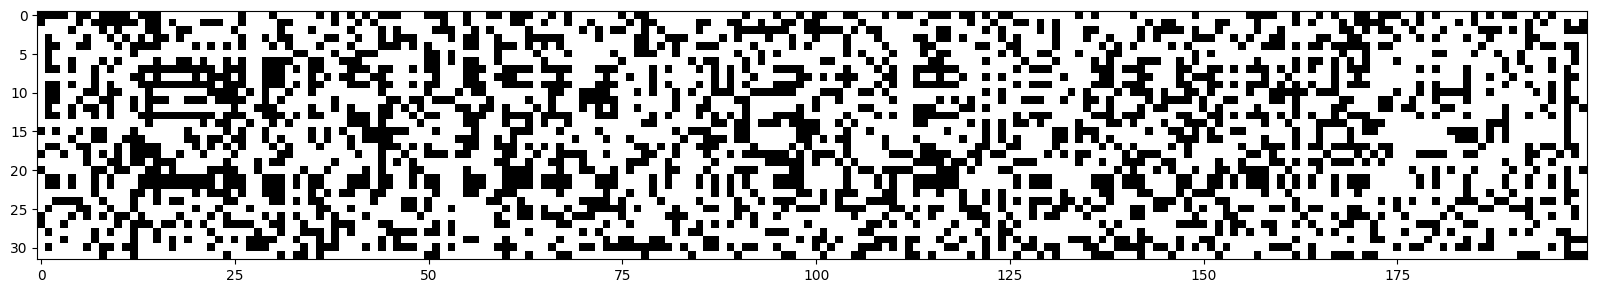

In [ ]:
plt.figure(figsize=(20,10))
plt.imshow(h.abs() > 0.99, cmap='gray', interpolation='nearest')

In the above graph, each row represents some training input row in a minibatch, and each column represents a neuron. If a column is completely white, then none the training data in that batch can cause a gradient update within the neuron. The big problem is when nothing in the training data can activate a neuron anymore, because then it is basically taken out of the model.

NOTE: This can also happen during optimization, by moving the parameters into a spot such that a neuron is now dead from that point onwards. Still not great, can occur with very high learning rates.

So, having dead neurons = losing computing power, which we do not want, especially at initialization. It's much better to have the model be activated by more training examples = more training and potential faster/better optimization.

In [ ]:
# MLP revisited
n_embd = 10 # the dimensionality of the character embedding vectors
n_hidden = 200 # the number of neurons in the hidden layer of the MLP

g = torch.Generator().manual_seed(2147483647) # for reproducibility
C  = torch.randn((vocab_size, n_embd),            generator=g)
W1 = torch.randn((n_embd * block_size, n_hidden), generator=g) * 0.01
b1 = torch.randn(n_hidden,                        generator=g) * 0.01
W2 = torch.randn((n_hidden, vocab_size),          generator=g) * 0.01 # reducing magnitude
b2 = torch.randn(vocab_size,                      generator=g) * 0 #initializing at 0

parameters = [C, W1, b1, W2, b2]
print(sum(p.nelement() for p in parameters)) # number of parameters in total
for p in parameters:
  p.requires_grad = True

11897


In [ ]:
# same optimization as last time
max_steps = 200000
batch_size = 32
lossi = []

for i in range(max_steps):

  # minibatch construct
  ix = torch.randint(0, Xtr.shape[0], (batch_size,), generator=g)
  Xb, Yb = Xtr[ix], Ytr[ix] # batch X,Y

  # forward pass
  emb = C[Xb] # embed the characters into vectors
  embcat = emb.view(emb.shape[0], -1) # concatenate the vectors
  hpreact = embcat @ W1 + b1 # hidden layer pre-activation
  h = torch.tanh(hpreact) # hidden layer
  logits = h @ W2 + b2 # output layer
  loss = F.cross_entropy(logits, Yb) # loss function

  # backward pass
  for p in parameters:
    p.grad = None
  loss.backward()

  # update
  lr = 0.1 if i < 100000 else 0.01 # step learning rate decay
  for p in parameters:
    p.data += -lr * p.grad

  # track stats
  if i % 10000 == 0: # print every once in a while
    print(f'{i:7d}/{max_steps:7d}: {loss.item():.4f}')
  lossi.append(loss.log10().item())

      0/ 200000: 3.2972
  10000/ 200000: 2.1634
  20000/ 200000: 2.3241
  30000/ 200000: 2.4002
  40000/ 200000: 1.9654
  50000/ 200000: 2.6275
  60000/ 200000: 2.3651
  70000/ 200000: 2.0442
  80000/ 200000: 2.2509
  90000/ 200000: 2.1626
 100000/ 200000: 1.9017
 110000/ 200000: 2.2478
 120000/ 200000: 1.9956
 130000/ 200000: 2.5327
 140000/ 200000: 2.4242
 150000/ 200000: 2.3073
 160000/ 200000: 1.9175
 170000/ 200000: 1.7827
 180000/ 200000: 2.0672
 190000/ 200000: 1.7780


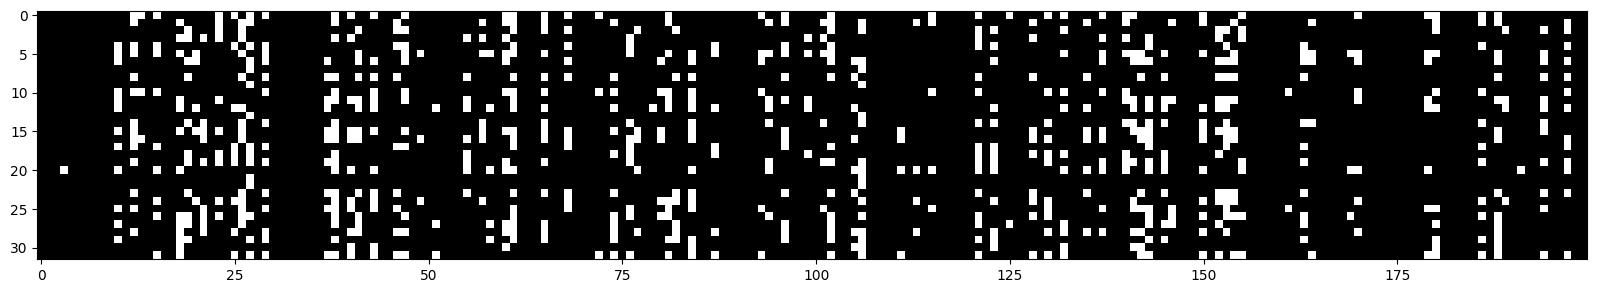

In [ ]:
plt.figure(figsize=(20,10))
plt.imshow(h.abs() > 0.99, cmap='gray', interpolation='nearest') # much more black

So, to avoid wasting neurons early on, we want to reduce the spread of possible values of h pre-activation, so that after applying tanh they don't go to |1|. We achieve this by simply multiplying by a fraction, but there are more principled ways to go about it.

In [ ]:
x = torch.randn(1000, 10)
w = torch.randn(10, 200)
y = x @ w
print(x.mean(), x.std())
print(w.mean(), w.std())
print(y.mean(), y.std()) # y has a greater STD than x,w

tensor(0.0066) tensor(1.0050)
tensor(0.0194) tensor(1.0125)
tensor(0.0185) tensor(3.2186)


In [ ]:
x = torch.randn(1000, 10)
w = torch.randn(10, 200) * 0.2
y = x @ w
print(x.mean(), x.std())
print(w.mean(), w.std())
print(y.mean(), y.std()) # scaling w down reduces STD of both w and y

tensor(-0.0056) tensor(1.0049)
tensor(0.0026) tensor(0.2005)
tensor(0.0005) tensor(0.6356)


If scaling down the magnitude of w reduces the spread of y, the question becomes:

what are the parameters of the normal distribution that we want to multiply x with so that y maintains the same STD?

The principled answer is to divide by the square root of the fan-in (number of input elements)

In [ ]:
x = torch.randn(1000, 10)
w = torch.randn(10, 200) / (10 ** 0.5)
y = x @ w
print(x.mean(), x.std())
print(w.mean(), w.std())
print(y.mean(), y.std())

tensor(0.0034) tensor(0.9922)
tensor(0.0063) tensor(0.3169)
tensor(-0.0037) tensor(0.9958)


This weights initialization can be automatically done with torch.nn.init.kaiming_normal_

In [ ]:
# MLP revisited
n_embd = 10 # the dimensionality of the character embedding vectors
n_hidden = 200 # the number of neurons in the hidden layer of the MLP

g = torch.Generator().manual_seed(2147483647) # for reproducibility
C  = torch.randn((vocab_size, n_embd),            generator=g)
W1 = torch.randn((n_embd * block_size, n_hidden), generator=g) * (5/3)/((n_embd * block_size)**0.5) # kaiming_init
b1 = torch.randn(n_hidden,                        generator=g) * 0.01
W2 = torch.randn((n_hidden, vocab_size),          generator=g) * 0.01
b2 = torch.randn(vocab_size,                      generator=g) * 0

parameters = [C, W1, b1, W2, b2]
print(sum(p.nelement() for p in parameters)) # number of parameters in total
for p in parameters:
  p.requires_grad = True

11897


In [ ]:
# same optimization as last time
max_steps = 200000
batch_size = 32
lossi = []

for i in range(max_steps):

  # minibatch construct
  ix = torch.randint(0, Xtr.shape[0], (batch_size,), generator=g)
  Xb, Yb = Xtr[ix], Ytr[ix] # batch X,Y

  # forward pass
  emb = C[Xb] # embed the characters into vectors
  embcat = emb.view(emb.shape[0], -1) # concatenate the vectors
  hpreact = embcat @ W1 + b1 # hidden layer pre-activation
  h = torch.tanh(hpreact) # hidden layer
  logits = h @ W2 + b2 # output layer
  loss = F.cross_entropy(logits, Yb) # loss function

  # backward pass
  for p in parameters:
    p.grad = None
  loss.backward()

  # update
  lr = 0.1 if i < 100000 else 0.01 # step learning rate decay
  for p in parameters:
    p.data += -lr * p.grad

  # track stats
  if i % 10000 == 0: # print every once in a while
    print(f'{i:7d}/{max_steps:7d}: {loss.item():.4f}')
  lossi.append(loss.log10().item())

      0/ 200000: 3.3179
  10000/ 200000: 2.1910
  20000/ 200000: 2.3270
  30000/ 200000: 2.5396
  40000/ 200000: 1.9468
  50000/ 200000: 2.3331
  60000/ 200000: 2.3852
  70000/ 200000: 2.1173
  80000/ 200000: 2.3159
  90000/ 200000: 2.2010
 100000/ 200000: 1.8591
 110000/ 200000: 2.0881
 120000/ 200000: 1.9389
 130000/ 200000: 2.3913
 140000/ 200000: 2.0949
 150000/ 200000: 2.1458
 160000/ 200000: 1.7824
 170000/ 200000: 1.7249
 180000/ 200000: 1.9752
 190000/ 200000: 1.8614


We should note that the precise setting of the hidden layer preactivation is not *quite* as important now as it was some years ago, due to some modern innovations that we have gotten since. One of them is batch normalization:

The Idea: For the pre-activation hidden layer outputs, we are playing a balancing game where we don't want them to be too small (or else the tanh does nothing) or too big (or else we could get dead neurons). We actually just want the outputs to be Gaussian, and it is possible to just normalize these outputs to be Gaussian. The normalization process is exactly the same as how any normal pdf is normalized - by substracting the mean and dividing by the std.

In [ ]:
hpreact.shape

torch.Size([32, 200])

In [ ]:
((hpreact - hpreact.mean(0, keepdim=True)) / hpreact.std(0, keepdim=True)).shape

torch.Size([32, 200])

In [ ]:
((hpreact - hpreact.mean(0, keepdim=True)) / hpreact.std(0, keepdim=True)) # = hpreact


tensor([[ 2.0941,  0.7237, -0.3143,  ..., -0.3450,  1.5597,  0.8787],
        [ 1.0818, -0.2446, -0.8508,  ..., -1.4846,  0.4142, -0.1977],
        [-1.0175,  1.8772, -0.8015,  ...,  0.4670, -0.8823,  0.3219],
        ...,
        [ 0.4328, -1.1144, -0.6281,  ...,  0.4222, -0.4928, -1.2081],
        [ 0.2234,  0.8582,  1.9919,  ..., -0.6841, -0.5073,  0.8941],
        [-0.0935, -0.4629, -3.0977,  ...,  0.4948, -0.6826, -0.2203]],
       grad_fn=<DivBackward0>)

I could substitute this line directly into the training process and run the code, but the model performance wouldn't be great. This is because, while at initialization we want Gaussian h outputs, we don't want to force the model to always keep the outputs Gaussian - backpropagation should freely adjust the distribution of h. To do this, we implement a gain that scales to the normalized outputs, then offset them by some bias.

In [ ]:
bngain = torch.ones((1, n_hidden))
bnbias = torch.zeros((1, n_hidden))
parameters = [C, W1, b1, W2, b2, bngain, bnbias]
for p in parameters:
  p.requires_grad = True
# these exist to allow the neural net to move around and not necessarily stay Gaussian throughout training process
# why 1 though? backpropagation allows for bngain/bias to be modified, and change hpreact distribution

In [ ]:
# same optimization as last time
max_steps = 200000
batch_size = 32
lossi = []

for i in range(max_steps):

  # minibatch construct
  ix = torch.randint(0, Xtr.shape[0], (batch_size,), generator=g)
  Xb, Yb = Xtr[ix], Ytr[ix] # batch X,Y

  # forward pass
  emb = C[Xb] # embed the characters into vectors
  embcat = emb.view(emb.shape[0], -1) # concatenate the vectors
  hpreact = embcat @ W1 + b1 # hidden layer pre-activation
  hpreact = bngain * ((hpreact - hpreact.mean(0, keepdim=True)) / hpreact.std(0, keepdim=True)) + bnbias
  h = torch.tanh(hpreact) # hidden layer
  logits = h @ W2 + b2 # output layer
  loss = F.cross_entropy(logits, Yb) # loss function

  # backward pass
  for p in parameters:
    p.grad = None
  loss.backward()

  # update
  lr = 0.1 if i < 100000 else 0.01 # step learning rate decay
  for p in parameters:
    #print(lr, p, p.grad)
    p.data += -lr * p.grad

  # track stats
  if i % 10000 == 0: # print every once in a while
    print(f'{i:7d}/{max_steps:7d}: {loss.item():.4f}')
  lossi.append(loss.log10().item())

      0/ 200000: 2.0477
  10000/ 200000: 2.3377
  20000/ 200000: 2.2143
  30000/ 200000: 2.0598
  40000/ 200000: 2.2312
  50000/ 200000: 2.1545
  60000/ 200000: 2.5099
  70000/ 200000: 1.6324
  80000/ 200000: 2.3370
  90000/ 200000: 1.9932
 100000/ 200000: 2.1392
 110000/ 200000: 1.8231
 120000/ 200000: 2.4937
 130000/ 200000: 2.5673
 140000/ 200000: 2.2320
 150000/ 200000: 2.7072
 160000/ 200000: 2.0789
 170000/ 200000: 1.7426
 180000/ 200000: 2.0244
 190000/ 200000: 2.0744


NOTE: Batch normalization isn't necessarily expected to lead to gains here, mostly because we have already hand-calculated the weight/bias shifting needed to get approximately Gaussian anyway. However, for larger neural nets, it is easier to add batchnorm layers instead of hand-calculating the needed mean and std.

NOTE: The purpose of a neural net, after training, is to deploy it and have the model produce some output given some input. However, in this situation, we no longer feed in a minibatch as input to calculate the batch mean and std. The model relies on these values (we just input them earlier), so we need to provide a substitute. We achieve this by calculating the batch statistics after model training tht we feed in during inference.

In [ ]:
with torch.no_grad():
  emb = C[Xtr]
  embcat = emb.view(emb.shape[0], -1)
  hpreact = embcat @ W1 + b1

  bnmean = hpreact.mean(0, keepdim=True)
  bnstd = hpreact.std(0, keepdim=True) # fixed mean and std over entire training set, done after training to use at test time

@torch.no_grad() # this decorator disables gradient tracking
def split_loss(split):
  x,y = {
    'train': (Xtr, Ytr),
    'val': (Xdev, Ydev),
    'test': (Xte, Yte),
  }[split]
  emb = C[x]
  embcat = emb.view(emb.shape[0], -1)
  hpreact = embcat @ W1 + b1
  hpreact = bngain * ((hpreact - bnmean) / bnstd) + bnbias # batchnorm at test time

  h = torch.tanh(hpreact) # (N, n_hidden)
  logits = h @ W2 + b2 # (N, vocab_size)
  loss = F.cross_entropy(logits, y)
  print(split, loss.item())

split_loss('train')
split_loss('val')

train 2.04852557182312
val 2.101534366607666


In [ ]:
# second version that estimates bnmean and bnstd for test time inference during training

# same optimization as last time
max_steps = 200000
batch_size = 32
lossi = []

for i in range(max_steps):

  # minibatch construct
  ix = torch.randint(0, Xtr.shape[0], (batch_size,), generator=g)
  Xb, Yb = Xtr[ix], Ytr[ix] # batch X,Y

  # forward pass
  emb = C[Xb] # embed the characters into vectors
  embcat = emb.view(emb.shape[0], -1) # concatenate the vectors
  hpreact = embcat @ W1 + b1 # hidden layer pre-activation
  hpreact = bngain * ((hpreact - hpreact.mean(0, keepdim=True)) / hpreact.std(0, keepdim=True)) + bnbias
  h = torch.tanh(hpreact) # hidden layer
  logits = h @ W2 + b2 # output layer
  loss = F.cross_entropy(logits, Yb) # loss function

  # backward pass
  for p in parameters:
    p.grad = None
  loss.backward()

  # update
  lr = 0.1 if i < 100000 else 0.01 # step learning rate decay
  for p in parameters:
    #print(lr, p, p.grad)
    p.data += -lr * p.grad

  # track stats
  if i % 10000 == 0: # print every once in a while
    print(f'{i:7d}/{max_steps:7d}: {loss.item():.4f}')
  lossi.append(loss.log10().item())